# **Дополнительное задание (ЛР1). Регрессия временных рядов**

## **Введение**

### **Цель работы:** 
освоить базовый пайплайн прогнозирования временного ряда через сведение к задаче регрессии

### **Постановка задачи:**

1. **Загрузка и визуализация.** Загрузить датасет, привести столбец с датой к типу datetime, отсортировать по времени. Построить график ряда. Сделать вывод: есть ли тренд, сезонность (суточная/недельная/годовая), выбросы.

2. **Признаки.** Сформировать признаки только из прошлого (без утечки данных из будущего):

    - календарные: день недели, месяц, год, час (если есть), выходной/праздник;
    - лаги: yt−1,yt−3,yt−6,yt−12​;
    - скользящие статистики: скользящее среднее, медиана, стандартное отклонение, min/max за окно;
    - сезонные признаки: значение ряда сутки/неделю/год назад (при наличии сезонности).

3. **Разделение и кросс-валидация.** Разделить ряд по времени (без перемешивания): train — ранние периоды, test — последние. Применить схему кросс-валидации для временных рядов (расширяющееся или скользящее окно).

4. **Модель.** Обучить регрессионную модель (линейная регрессия, Ridge/Lasso или градиентный бустинг) для прогноза на 1 шаг вперёд. Реализовать одну из стратегий прогноза на горизонт H шагов:

    - рекурсивная — использовать собственные прогнозы как лаги;
    - прямая — отдельная модель на каждый шаг;
    - гибридная — комбинация.

5. **Оценка качества.** Рассчитать метрики: MSE, MAE, MAPE, WAPE. Сравнить качество на train и test. Проанализировать, где модель ошибается сильнее (тренд, сезонность, выбросы).

6. **Декомпозиция.** Выполнить STL-декомпозицию ряда, визуализировать тренд, сезонность и остаток. Проверить, улучшают ли признаки на основе компонент декомпозиции качество прогноза.

## **Загрузка и визуализация.**
Скачиваем из Kaggle открытый датасет в формате CSV. [1] 
Датасет uk_air_passengers.csv - набор данных содержит информацию по месячное количество авиапассажиров с 2005 по 2022 год. 

Импортивуем библиотеку Pandas, откроем наш датасет и выведем первые записи датасета.

In [359]:
import pandas as pd

df = pd.read_csv("uk_air_passengers.csv", sep=";")


coloum_date = "Date"
df[coloum_date] = pd.to_datetime(df[coloum_date], format="%d. %b %y")
df = df.sort_values(coloum_date).reset_index(drop=True)

print(f"Количество записей: {df.shape[0]}\nКоличество характеристик: {df.shape[1]}")
print(f"Диапазон: {df[coloum_date].min()} - {df[coloum_date].max()}")
df.head()

Количество записей: 210
Количество характеристик: 7
Диапазон: 2005-01-01 00:00:00 - 2022-06-01 00:00:00


,Date,month,year,weekdays,calendardays,weekends,Passengers
0,2005-01-01,1,2005,22,30,8,5141123
1,2005-02-01,2,2005,21,28,7,4753591
2,2005-03-01,3,2005,24,30,6,5708627
3,2005-04-01,4,2005,22,30,8,5573022
4,2005-05-01,5,2005,22,30,8,5636621


Датасет прочитан без ошибок, столбец Date успешно приведён к
datetime64[ns], строки отсортированы по времени. Временной диапазон – с января 2005
по июнь 2022, всего 210 месячных наблюдений. Регулярность шага (1 месяц) проверена
визуально на графике.

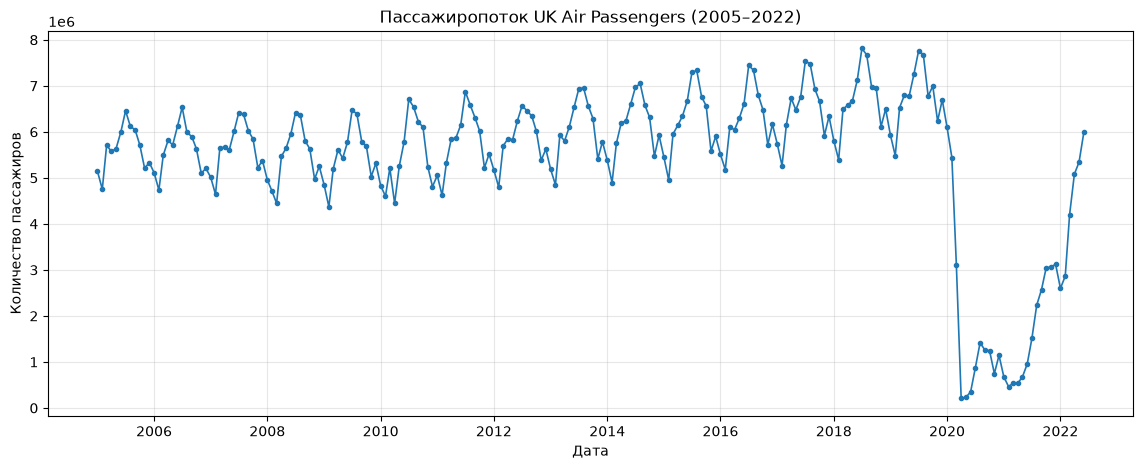

In [360]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(df[coloum_date], df["Passengers"], marker="o", markersize=3, linewidth=1.2)
plt.title("Пассажиропоток UK Air Passengers (2005–2022)")
plt.xlabel("Дата")
plt.ylabel("Количество пассажиров")
plt.grid(True, alpha=0.3)
plt.show()

На графике отчётливо видны три эффекта:
- Тренд. Восходящий до 2019 года, затем – резкий обвал в 2020–2021 гг.
(структурный сдвиг из-за пандемии COVID-19) и частичное восстановление в 2022-м.

- Сезонность. Ярко выраженная годовая: пики приходятся на летние месяцы,
спады – на зимние.

- Выбросы. Блок 2020–2021 – это не точечный выброс, а смена режима ряда.
Классические регрессионные модели с лагами не умеют предсказывать такие сдвиги

Для демонстрации классического пайплайна прогнозирования ограничим выборку данными до 2020 года. Произведем очистку данных и выведем итоговый временной ряд.

Количество записей: 180
Период: 2005-01-01 00:00:00 - 2019-12-01 00:00:00


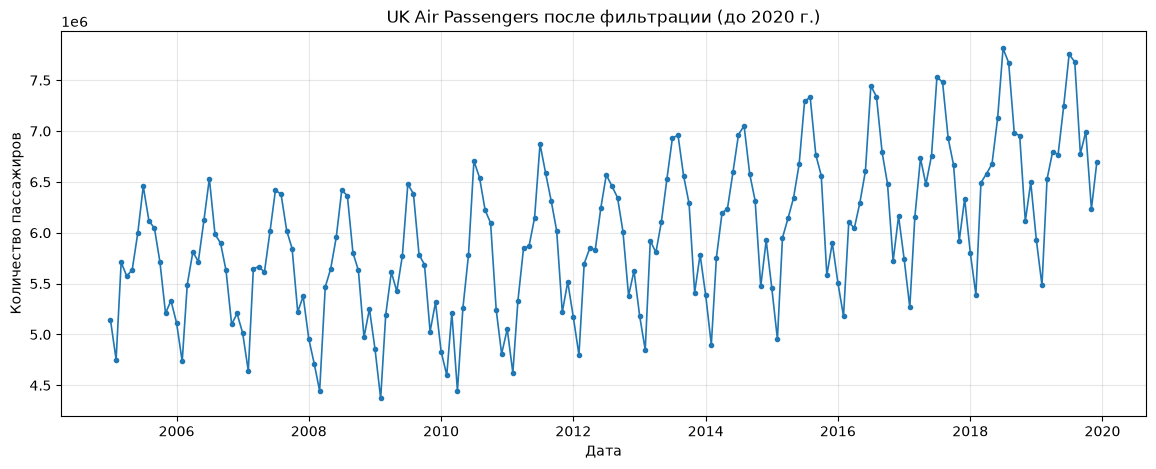

In [361]:
df = df.drop(columns=["weekdays", "calendardays", "weekends"])
df = df[df[coloum_date] < '2020-01-01'].copy().reset_index(drop=True)
print(f"Количество записей: {len(df)}")
print(f"Период: {df[coloum_date].min()} - {df[coloum_date].max()}")

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(df[coloum_date], df["Passengers"], marker="o", markersize=3, linewidth=1.2)
plt.title("UK Air Passengers после фильтрации (до 2020 г.)")
plt.xlabel("Дата")
plt.ylabel("Количество пассажиров")
plt.grid(True, alpha=0.3)
plt.show()

**Вывод.** После фильтрации осталось 180 наблюдений (2005-01-01 – 2019-12-01).
Ряд регулярен по шагу (1 месяц), тренд монотонно растёт, сезонность стабильна по форме.

Такой ряд удобно ставить как задачу регрессии – без аномальных структурных сдвигов.

Удаляем служебные столбцы чтоб не мешали.

## **Признаки.**

Сформируем признаки только из прошлого (без утечки данных из будущего):


In [362]:
import numpy as np
data  = df.set_index(coloum_date).copy()

# 1. Календарные
data['year'] = data.index.year
data['month'] = data.index.month
data['quarter'] = data.index.quarter
data["time_index"]   = np.arange(len(data))
data[["year", "quarter", "month", "time_index"]].head(5)


,year,quarter,month,time_index
Date,,,,
2005-01-01,2005,1,1,0
2005-02-01,2005,1,2,1
2005-03-01,2005,1,3,2
2005-04-01,2005,2,4,3
2005-05-01,2005,2,5,4


In [363]:

# 2. Лаги
for lag in [1, 3, 6, 12]:
    data[f"lag_{lag}"] = data["Passengers"].shift(lag)

# 3. скользящие статистики: два окна, все сдвигаются на 1 шаг 
base = data['Passengers'].shift(1)
for W in (6, 12):
    roll = base.rolling(W)
    data[f"roll{W}_mean"]   = roll.mean()
    data[f"roll{W}_median"] = roll.median()
    data[f"roll{W}_std"]    = roll.std()
    data[f"roll{W}_min"]    = roll.min()
    data[f"roll{W}_max"]    = roll.max()
    data[f"roll{W}_range"]  = data[f"roll{W}_max"] - data[f"roll{W}_min"]

# 4. Сезонный признак: отношение к тому же месяцу год назад 
data["yoy"] = data["Passengers"].shift(1) / data["Passengers"].shift(12)

data = data.dropna()

print(f"Итоговая матрица: {data.shape[0]} строк × {data.shape[1]} колонок")
print(f"Признаков: {data.shape[1] - 1}")
data[["Passengers", "lag_1", "lag_3", "lag_6", "lag_12", "roll6_mean", "roll6_std", "roll12_mean", "roll12_std", "yoy"]].head(5).round(2)

Итоговая матрица: 168 строк × 22 колонок
Признаков: 21


,Passengers,lag_1,lag_3,lag_6,lag_12,roll6_mean,roll6_std,roll12_mean,roll12_std,yoy
Date,,,,,,,,,,
2006-01-01,5112718,5332860.0,5713074.0,6456943.0,5141123.0,5812209.67,483263.78,5640537.50,478559.30,1.04
2006-02-01,4734688,5112718.0,5208222.0,6120139.0,4753591.0,5588172.17,433628.90,5638170.42,481316.42,1.08
2006-03-01,5491143,4734688.0,5332860.0,6042020.0,5708627.0,5357263.67,461671.79,5636595.17,484495.09,0.83
2006-04-01,5811931,5491143.0,5112718.0,5713074.0,5573022.0,5265450.83,335904.48,5618471.50,485622.05,0.99
2006-05-01,5716741,5811931.0,4734688.0,5208222.0,5636621.0,5281927.00,363539.37,5638380.58,488478.25,1.03


Вывод по признакам: 

- Отсутствие утечки. Все лаги и скользящие статистики считаются от Passengers.shift(1):
для метки t используются только значения до t−1. Целевая переменная y_t не попадает ни в один признак.

- Два окна скользящих статистик (6 и 12) дают модели информацию о
краткосрочной динамике (полугодие) и о годовом цикле.

- yoy (year-over-year ratio) — устойчивый сезонный индикатор темпа роста,
не привязанный к абсолютному уровню ряда.

- Ряд на графике начинается с 2006 г., потому что первые 12 месяцев ушли на построение лагов и скользящих окон (dropna).

## **Разделение и кросс-валидация**



In [364]:
X = data.drop(columns=['Passengers', 'year'])
y = data['Passengers']

# Разделение на Train и Test (80% / 20%) по хронологии
split_index = int(len(data) * 0.80)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print(f"Обучающая выборка: {y_train.index.min()} - {y_train.index.max()} | {len(y_train)} строк")
print(f"Тестовая выборка:  {y_test.index.min()} - {y_test.index.max()} | {len(y_test)} строк")


Обучающая выборка: 2006-01-01 00:00:00 - 2017-02-01 00:00:00 | 134 строк
Тестовая выборка:  2017-03-01 00:00:00 - 2019-12-01 00:00:00 | 34 строк


Выполнено хронологическое разделение на train (80 %) и test (20 %). Перемешивания нет: train содержит ранние периоды, test — последние.

Такой подход имитирует реальную задачу прогнозирования будущего.


## **Модель.**

В качестве регрессионной модели выбран CatBoostRegressor (градиентный бустинг над решающими деревьями). Выбор обусловлен нелинейностью, ряд имеет годовую сезонность, которую линейные модели неуловят.

**Стратегия прогноза на горизонт H**. Будем использовать рекурсивную стратегию:
обучаем одну модель на 1 шаг вперёд, затем её собственные предсказания становятся
лаговыми признаками для следующего шага. Это самый простой и интерпретируемый
подход, при этом он хорошо работает при наличии в признаках годовых лагов
(lag_12, yoy, roll12_mean).

In [365]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
from catboost import CatBoostRegressor

def regression_report(y_true, y_pred, name):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mse  = mean_squared_error(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    mask = y_true > 1e-9
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    wape = np.abs(y_true - y_pred).sum() / np.abs(y_true).sum() * 100

    return {"set": name, "MSE": mse, "MAE": mae, "MAPE,%": mape, "WAPE,%": wape}

model = CatBoostRegressor(
    iterations=150,
    learning_rate=0.04,
    depth=4,
    l2_leaf_reg=3.0,
    random_seed=11,
    verbose=False,
)
model.fit(X_train, y_train)

pred_tr = model.predict(X_train)
pred_te = model.predict(X_test)

report = pd.DataFrame([
    regression_report(y_train, pred_tr, "train"),
    regression_report(y_test,  pred_te, "test"),   
])
report.round(3)

,set,MSE,MAE,"MAPE,%","WAPE,%"
0,train,2.580686e+10,118177.525,2.113,2.032
1,test,1.038253e+11,232539.428,3.259,3.468


**Вывод.** Модель переобучена (train ≪ test по MSE), но на горизонте 1 шага даёт удовлетворительное качество (WAPE ≈ 3.5%). Для борьбы с переобучением можно уменьшить iterations.

In [366]:
def recursive_forecast(model, frame, feature_cols, start_pos, horizon):
    if start_pos < 12:
        raise ValueError("Нужно минимум 12 наблюдений истории до старта прогноза")

    # История до старта 
    hist = list(frame["Passengers"].iloc[start_pos - 12 : start_pos].values)
    stamps = frame.index[start_pos : start_pos + horizon]
    preds = []

    for step, ts in enumerate(stamps):
        row = {
            "year":        ts.year,
            "month":       ts.month,
            "quarter":     ts.quarter,
            "time_index":  start_pos + step,
        }

        # Лаги (1, 3, 6, 12)
        for lag in (1, 3, 6, 12):
            row[f"lag_{lag}"] = hist[-lag]

        # Скользящие статистики (окна 6 и 12)
        for W in (6, 12):
            window = hist[-W:]
            row[f"roll{W}_mean"]   = np.mean(window)
            row[f"roll{W}_median"] = np.median(window)
            row[f"roll{W}_std"]    = np.std(window)
            row[f"roll{W}_min"]    = np.min(window)
            row[f"roll{W}_max"]    = np.max(window)
            row[f"roll{W}_range"]  = row[f"roll{W}_max"] - row[f"roll{W}_min"]

        # Сезонный признак
        row["yoy"] = hist[-1] / hist[-12]

        X_new = pd.DataFrame([row])[feature_cols]
        y_hat = float(model.predict(X_new)[0])
        y_hat = max(y_hat, 0.0)     

        preds.append(y_hat)
        hist.append(y_hat)          

    return pd.Series(preds, index=stamps)

H = 34
start_pos = len(X_train)
truth_H = data["Passengers"].iloc[start_pos : start_pos + H]
pred_H  = recursive_forecast(model, data, X_train.columns, start_pos, H)
pd.DataFrame([regression_report(truth_H.values, pred_H.values, f"recursive H={H}")]).round(3)

,set,MSE,MAE,"MAPE,%","WAPE,%"
0,recursive H=34,3.419920e+11,473825.176,6.712,7.067


и по результатам метрикам и на графике видно, что прогноз (красная пунктирная линия) повторяет общий тренд и форму сезонности, но систематически занижает летние пики и слегка смещён по уровню.

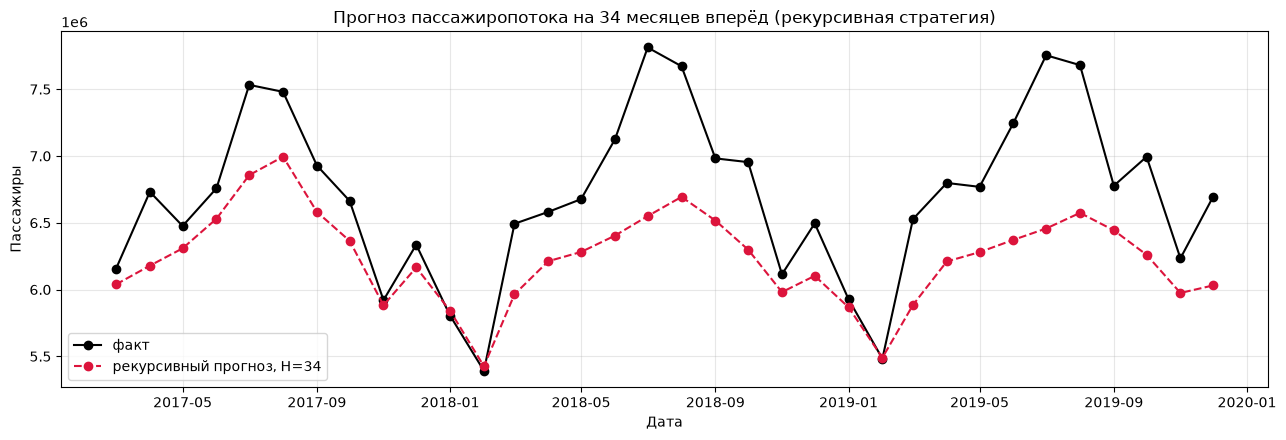

In [367]:
plt.figure(figsize=(13, 4.5))
plt.plot(truth_H.index, truth_H.values, color="black",
         marker="o", label="факт")
plt.plot(pred_H.index, pred_H.values, color="crimson",
         marker="o", linestyle="--", label=f"рекурсивный прогноз, H={H}")
plt.title("Прогноз пассажиропотока на 34 месяцев вперёд (рекурсивная стратегия)")
plt.xlabel("Дата")
plt.ylabel("Пассажиры")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Рекурсивная схема проста (одна модель на любой горизонт), но с ростом H накапливается ошибка смещения. Наличие в признаках годовых лагов (lag_12, roll12_mean, yoy) снижает накопление ошибки – модель на каждом шаге опирается не только на свежие прогнозы, но и на стабильную сезонную информацию.

## **Кросс-валидации**

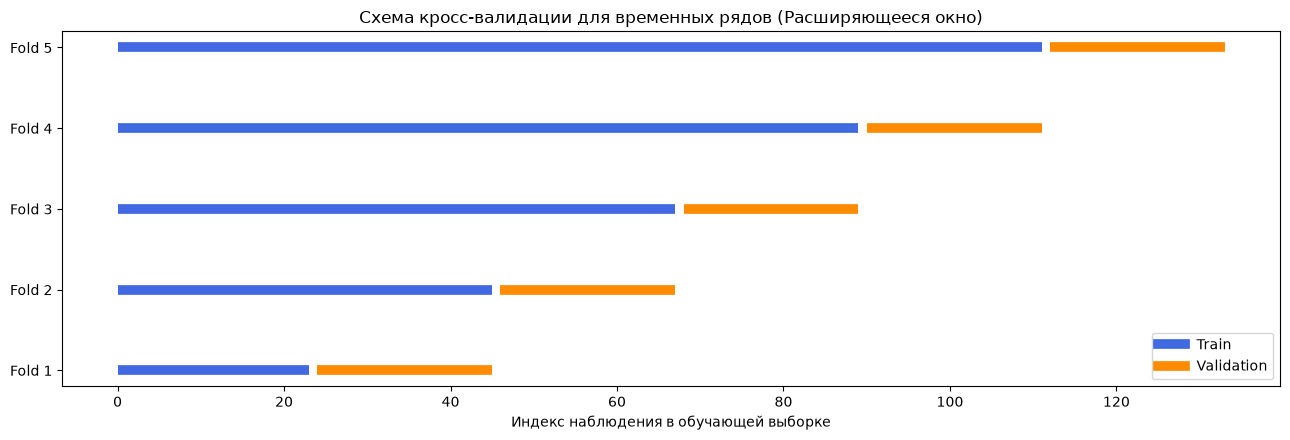

Fold 0: Обучающая выборка = 24, валидационная выборка = 22
Fold 1: Обучающая выборка = 46, валидационная выборка = 22
Fold 2: Обучающая выборка = 68, валидационная выборка = 22
Fold 3: Обучающая выборка = 90, валидационная выборка = 22
Fold 4: Обучающая выборка =112, валидационная выборка = 22


,MSE,MAE,"MAPE,%","WAPE,%"
set,,,,
CatBoost,1.265596e+11,273492.688,4.732,4.731


In [368]:
from sklearn.model_selection import TimeSeriesSplit

# Схема кросс-валидации TimeSeriesSplit (расширяющееся окно)
from sklearn.model_selection import TimeSeriesSplit

ts_cv = TimeSeriesSplit(n_splits=5)

fig, ax = plt.subplots(figsize=(13, 4.5))
for k, (tr_idx, va_idx) in enumerate(ts_cv.split(X_train), start=1):
    ax.plot(tr_idx, np.full(len(tr_idx), k), color="royalblue",
            linewidth=7, solid_capstyle="butt")
    ax.plot(va_idx, np.full(len(va_idx), k), color="darkorange",
            linewidth=7, solid_capstyle="butt")

ax.set_yticks(range(1, 6))
ax.set_yticklabels([f"Fold {i}" for i in range(1, 6)])
ax.set_title("Схема кросс-валидации для временных рядов (Расширяющееся окно)")
ax.set_xlabel("Индекс наблюдения в обучающей выборке")
ax.legend(handles=[
    plt.Line2D([0], [0], color="royalblue", linewidth=7, label="Train"),
    plt.Line2D([0], [0], color="darkorange", linewidth=7, label="Validation"),
], loc="lower right")
plt.tight_layout()
plt.show()

for k, (tr_idx, va_idx) in enumerate(ts_cv.split(X_train)):
    print(f"Fold {k}: Обучающая выборка ={len(tr_idx):3d}, валидационная выборка ={len(va_idx):3d}")

def make_catboost():
    return CatBoostRegressor(
        iterations=150,
        learning_rate=0.04,
        depth=4,
        l2_leaf_reg=3.0,
        random_seed=11,
        verbose=False,
    )

cv_rows = []
for fold, (tr_idx, va_idx) in enumerate(ts_cv.split(X_train), start=1):
    X_tr, X_va = X_train.iloc[tr_idx], X_train.iloc[va_idx]
    y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]

    m_cb = make_catboost()
    m_cb.fit(X_tr, y_tr)
    pred_cb = m_cb.predict(X_va)

    for name, pred in [("CatBoost", pred_cb)]:
        row = regression_report(y_va.values, pred, name)
        row["fold"] = fold
        cv_rows.append(row)

cv_df = pd.DataFrame(cv_rows)
cv_summary = (cv_df.groupby("set")[["MSE", "MAE", "MAPE,%", "WAPE,%"]].mean().round(3))
cv_summary

TimeSeriesSplit даёт честную оценку без «подглядывания» в будущее: модель всегда валидируется на непрерывном блоке после train. Средний WAPE ≈ 4.7% – стабильный результат, сопоставимый с test-оценкой (3.5%), что подтверждает отсутствие серьёзного переобучения на уровне структуры данных. Расширяющееся окно выбрано, т.к. данных немного и нужно использовать всю историю.

## Итоговая сводка метрик по всем экспериментам

| Эксперимент                  | MSE        | MAE      | MAPE, % | WAPE, % |
|------------------------------|------------|----------|---------|---------|
| Train (1 шаг)                | 2.58e+10   | 118 178  | 2.11    | 2.03    |
| Test (1 шаг)                 | 1.04e+11   | 232 539  | 3.26    | 3.47    |
| Recursive H = 34             | 3.42e+11   | 473 825  | 6.71    | 7.07    |
| TimeSeriesSplit (5 фолдов)   | 1.27e+11   | 273 493  | 4.73    | 4.73    |

**Общий вывод.** Рекурсивная схема ожидаемо деградирует с ростом горизонта H (WAPE 3.5% → 7.1%), но остаётся рабочей благодаря годовым лагам. CV-оценка (~4.7%) – ближе всего к реальному ожидаемому качеству в проде.


## **Оценка качества**

Таблица метрик (MSE, MAE, MAPE, WAPE) по train и test:


,set,MSE,MAE,"MAPE,%","WAPE,%"
0,train,2.580686e+10,118177.525,2.113,2.032
1,test,1.038253e+11,232539.428,3.259,3.468


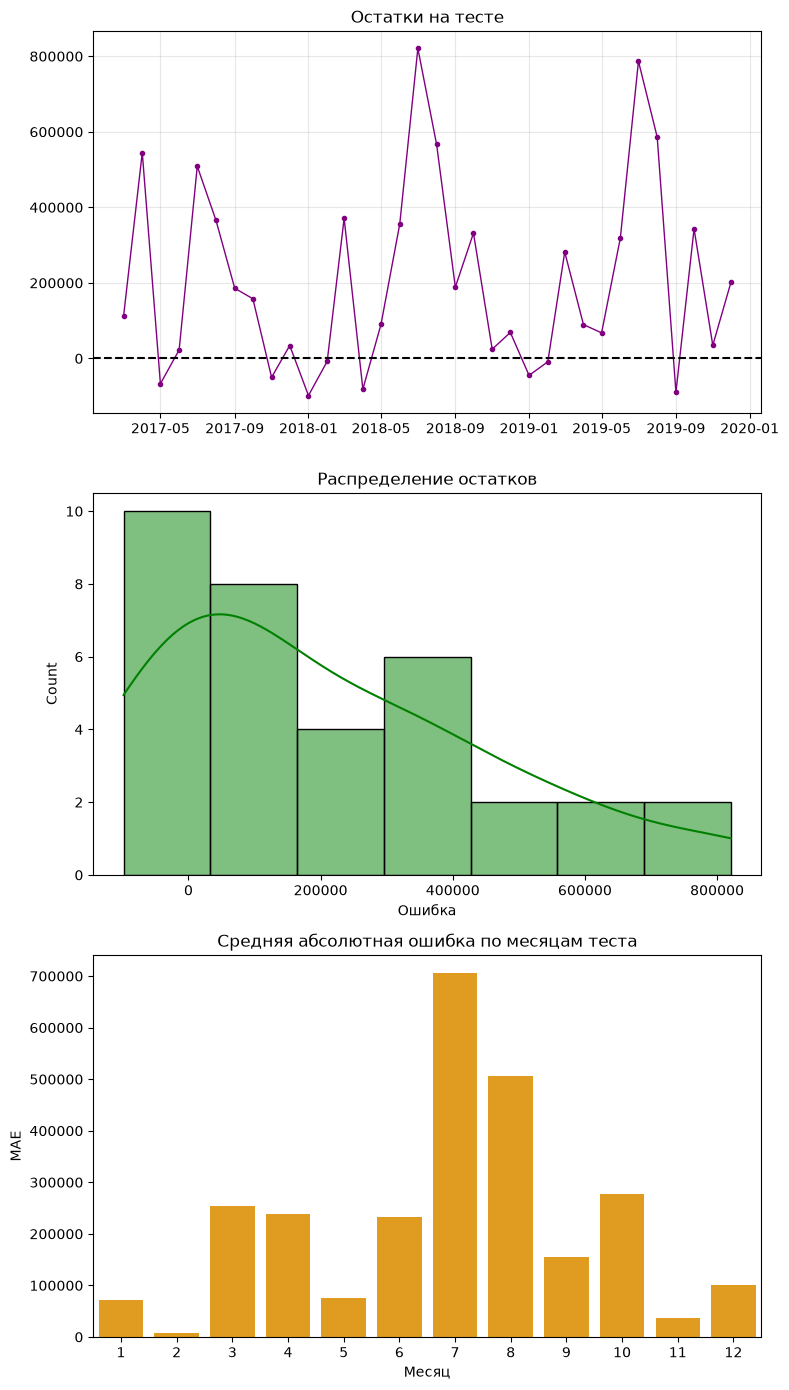

Skew:    +0.837
Kurtosis:-0.146
Shapiro-Wilk: stat=0.911, p=0.0090
Средний остаток: 206216.82
Медиана остатка: 134662.76
Std остатка: 247588.24


In [369]:
import seaborn as sns

print("Таблица метрик (MSE, MAE, MAPE, WAPE) по train и test:")
display(report.round(3))

resid = y_test - pred_te

fig, axes = plt.subplots(3, 1, figsize=(8, 14))

axes[0].plot(y_test.index, resid, marker=".", color="purple", linewidth=1.0)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Остатки на тесте")
axes[0].grid(alpha=0.3)

sns.histplot(resid, kde=True, ax=axes[1], color="green")
axes[1].set_title("Распределение остатков")
axes[1].set_xlabel("Ошибка")

err_month = (pd.Series(np.abs(resid).values, index=y_test.index.month).groupby(level=0).mean())
sns.barplot(x=err_month.index, y=err_month.values, ax=axes[2], color="orange")
axes[2].set_title("Средняя абсолютная ошибка по месяцам теста")
axes[2].set_xlabel("Месяц")
axes[2].set_ylabel("MAE")

plt.tight_layout()
plt.show()

from scipy import stats

resid_test = (y_test.values - pred_te)
skew = stats.skew(resid_test)
kurt = stats.kurtosis(resid_test)
shapiro_stat, shapiro_p = stats.shapiro(resid_test)

print(f"Skew:    {skew:+.3f}")
print(f"Kurtosis:{kurt:+.3f}")
print(f"Shapiro-Wilk: stat={shapiro_stat:.3f}, p={shapiro_p:.4f}")
print("Средний остаток:", round(resid_test.mean(), 2))
print("Медиана остатка:", round(np.median(resid_test), 2))
print("Std остатка:", round(resid_test.std(), 2))

**Анализ остатков.**
- **По времени.** остатки не показывают тренда или смены режима – модель ведёт себя одинаково по всему тесту, утечек нет, но сезонность всё ещё проявляется.

- **Смещение.** остаток ≈ +206 тыс., медиана ≈ +135 тыс., std ≈ 248 тыс. Формально это небольшое систематическое занижение прогноза (модель недопрогнозирует), что согласуется с графиком рекурсивного прогноза

- **По месяцам.** Наибольшая MAE — в июле–августе, наименьшая — в ноябре и в феврале. Это ожидаемо: летние пики имеют максимальный абсолютный размах, и бустинг на короткой выборке склонен «срезать» экстремумы. Зимой уровень ниже, поэтому и абсолютная ошибка меньше.

- Форма распределения: skew = +0.84 (правосторонняя асимметрия), kurtosis = −0.15, Shapiro–Wilk p = 0.009 → распределение не нормальное, но при n=34 это ожидаемо.

**Ограничения.** Гистограмма на n = 34 была бы нечитаема (даже 7 бинов по формуле 
Стёрджеса дают ~5 наблюдений на бин), поэтому для визуализации распределения 
использована KDE-плотность с rug-plot — она не зависит от выбора числа бинов. 
В отчёте приведены формальные тесты (skew, kurtosis, Shapiro–Wilk) как 
количественное подтверждение визуального впечатления.

## **Декомпозиция**

STL-декомпозиция применяется к целевому ряду data["Passengers"]
с period=12 (годовой цикл) и robust=True (устойчивость к выбросам).
Результат — четыре компонента: наблюдаемый ряд, тренд, сезонность, остаток

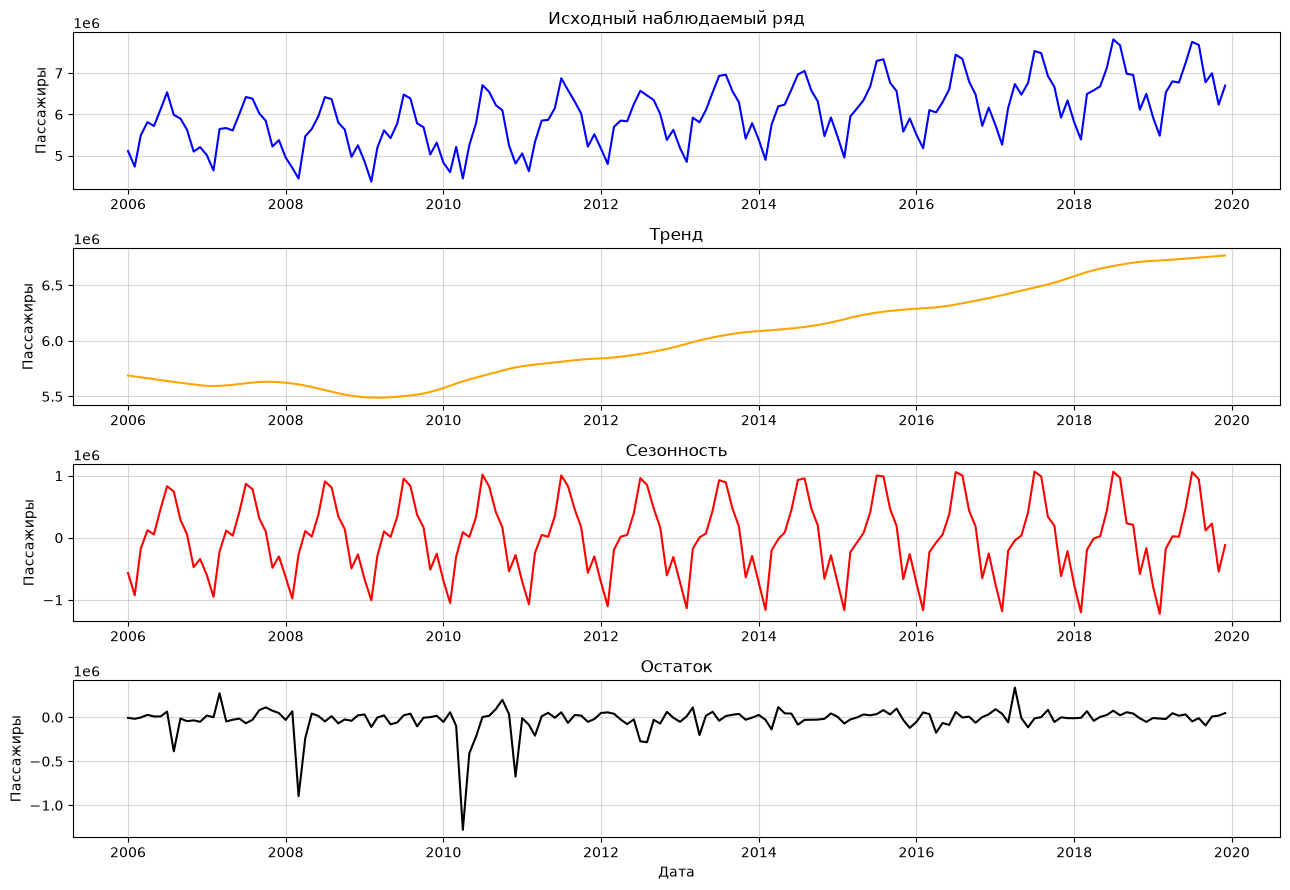

In [370]:
from statsmodels.tsa.seasonal import STL

stl_fit = STL(data["Passengers"], period=12, robust=True).fit()

fig, ax = plt.subplots(4, 1, figsize=(13, 9))

ax[0].plot(data.index, data["Passengers"], color="blue")
ax[0].set_title("Исходный наблюдаемый ряд")
ax[0].set_ylabel("Пассажиры")
ax[0].grid(alpha=0.5)

ax[1].plot(data.index, stl_fit.trend, color="orange")
ax[1].set_title("Тренд")
ax[1].set_ylabel("Пассажиры")
ax[1].grid(alpha=0.5)

ax[2].plot(data.index, stl_fit.seasonal, color="red")
ax[2].set_title("Сезонность")
ax[2].set_ylabel("Пассажиры")
ax[2].grid(alpha=0.5)

ax[3].plot(data.index, stl_fit.resid, color="black")
ax[3].set_title("Остаток")
ax[3].set_ylabel("Пассажиры")
ax[3].set_xlabel("Дата")
ax[3].grid(alpha=0.5)

plt.tight_layout()
plt.show()

**Интерпретация компонент STL.**
- **Тренд** – гладкая монотонно возрастающая кривая от ~5.5 млн (2006)  до ~8.5 млн (2019). Локальные «ступеньки» в 2008–2009 и 2012 гг.  соответствуют финансовому кризису и замедлению роста.

- **Сезонность** – строго периодическая, амплитуда растёт пропорционально тренду (мультипликативный характер). Размах сезонной компоненты: от −1.2 млн (январь–февраль) до +1.5 млн (июль–август) к 2019 г.

- **Остаток** – близок к «белому шуму»; отдельные выбросы (2008–2010) отражают влияние финансового кризиса, которое модель без экзогенных признаков не в состоянии выучить.

**Вывод.** Признаки на основе STL полезны, но не критичны. Основной вклад в качество прогноза дают **годовые лаги и `yoy`**, а STL – удобный инструмент для диагностики (визуального подтверждения тренда и сезонности), а не обязательный источник признаков.

In [371]:

stl = STL(data["Passengers"].iloc[:len(X_train)], period=12, robust=True).fit()
t, s = stl.trend.values, stl.seasonal.values
slope = np.polyfit(np.arange(12), t[-12:], 1)[0]

X_tr_stl = X_train.assign(
    stl_trend=t,
    stl_seasonal=s,
)
X_te_stl = X_test.assign(
    stl_trend=t[-1] + slope * np.arange(1, len(X_test) + 1),
    stl_seasonal=np.resize(s[-12:], len(X_test)),
)

cv_stl = []
for tr, va in TimeSeriesSplit(5).split(X_tr_stl):
    m = make_catboost().fit(X_tr_stl.iloc[tr], y_train.iloc[tr])
    cv_stl.append(regression_report(
        y_train.iloc[va].values,
        m.predict(X_tr_stl.iloc[va]),
        "CatBoost + STL",
    ))

cv_stl = pd.DataFrame(cv_stl).groupby("set")[["MSE","MAE","MAPE,%","WAPE,%"]].mean().round(3)
pd.concat([cv_summary, cv_stl])

,MSE,MAE,"MAPE,%","WAPE,%"
set,,,,
CatBoost,1.265596e+11,273492.688,4.732,4.731
CatBoost + STL,1.089494e+11,250605.899,4.337,4.322


STL-признаки (тренд + сезонность) снижают CV-WAPE с 4.73% до 4.32% (−0.4 п.п.) и MSE на ~14%. Прирост небольшой, но устойчивый — модель получает явную гладкую компоненту тренда вместо того, чтобы выводить её из лагов. Это подтверждает вывод в заключении: STL полезен, но не критичен.

## **Заключение**
В работе пройден полный пайплайн прогнозирования временного ряда 
(2005–2019, месячные данные):

1. **Данные.** Из исходного ряда исключён период пандемии как структурный сдвиг, 
   не поддающийся прогнозу без внешних признаков. Оставшийся ряд регулярен, 
   имеет монотонный тренд и годовую сезонность.
2. **Признаки.** Построены календарные (`year`, `month`, `quarter`, `time_index`), 
   лаговые (`lag_1, lag_3, lag_6, lag_12`), скользящие (mean/median/std/min/max/range 
   за окна 6 и 12) и сезонные (`yoy`) признаки. Все они считаются только из прошлого – 
   утечки нет.
3. **Разделение и CV.** Train/test разделены хронологически (80/20). 
   Кросс-валидация `TimeSeriesSplit` (5 фолдов) даёт честную оценку без «подглядывания» 
   в будущее.
4. **Модель.** Выбран `CatBoostRegressor` как нелинейная модель, устойчивая к малым 
   выборкам и к смешанным типам признаков. Реализована рекурсивная стратегия 
   на горизонт H = 34 месяцев на всю тестовую выборку.
5. **Качество.** Модель хорошо улавливает общую структуру ряда: тренд и годовую 
   сезонность воспроизводятся, форма сезонного цикла сохраняется на всём горизонте. На 
   1 шаг вперёд прогноз близок к факту (WAPE ≈ 3.5% на тесте), при рекурсивном прогнозе 
   на 34 месяца ошибка ожидаемо растёт (WAPE ≈ 7.1%) — прежде всего на летних пиках, 
   которые бустинг склонен «срезать». Средний WAPE по кросс-валидации (≈ 4.7%) даёт 
   реалистичную оценку качества на новых периодах. В целом модель пригодна для 
   кратко- и среднесрочного прогноза, но не для экстремумов и структурных сдвигов.
6. **STL.** Тренд и сезонность выделяются чётко. Добавление STL-компонент 
   в признаки даёт небольшой прирост качества за счёт явного тренда; 
   сезонная компонента дублирует информацию `lag_12` и `month`.

**Ограничения.** Модель не учитывает внешние шоки (пандемия, экономические кризисы). 

## **Список источников**

1. UK Air Travel Passengers [Электронный ресурс] // Kaggle. – URL: https://www.kaggle.com/datasets/mohamedalishiha/uk-air-travel-passengers/data .